# rf-indexed gates --- the v9 candidate (Phase 2 of the flat-years study)

**Question.** The funding-carry stack gates entry/exit on **absolute** trailing funding APR
(`theta_in = 8%`, `theta_keep = 2%`), thresholds fixed in the 2021 zero-rate world. The flat-years study
found the flat-year shortfall was, in 2023, a *hurdle* problem: the book collected +7.7% funding but kept
only +1.7% excess while T-bills paid ~5%, because the fixed gate held names whose carry merely matched cash.
The mechanism-first fix: make the gates **spreads over rf** --- `theta_in(t)=rf(t)+s_in`,
`theta_keep(t)=rf(t)+s_keep`. At `rf~0` (2021) this nests the incumbent exactly.

**Preregistered variant set** (declared before running; nothing else tried):

| variant | entry gate | keep gate | note |
|---|---|---|---|
| **BASE** | 8% (abs) | 2% (abs) | the incumbent (v6.1 stack + v4 overlay) --- parity-checked |
| **A** | rf + 8% | rf + 2% | incumbent spreads, indexed |
| **B** | rf + s_cost | rf + 1% | `s_cost` **derived** (round-trip cost amortized over BASE median hold + 2% buffer, rounded to the %) |
| **C** | rf + 8% | rf + 0% | asymmetric --- incumbent entry premium, keep only `>= rf` |

**The owner's concern, measured explicitly.** In high-rf years the indexed gate can be large vs funding
supply: 2024 `rf+8%` ~= 13% entry vs a ~16% median-funding cohort (does the raised *keep*-gate exit 2024
names too early and cost money?); 2025 `rf+8%` ~= 12% vs ~4% median supply (does the book barely deploy?).
With the v8 cash credit, sitting idle earns `rf`, so low deployment is only *bad* if it forgoes carry that
cleared the true hurdle. We quantify deployment / names / idle per year per variant.

**Method.** Lab-based (`../lab.py`, engine parity 1e-6), binance-only clean universe, the **full v6.1 stack
with the v4 overlay** (exact reconstruction from `../multiple_testing/_build_dsr_pbo.py` section 3a',
validated to reproduce stored v6.1 bit-for-bit). `lab.held_matrix` takes scalar thetas; a **time-varying-theta**
hysteresis is implemented below and unit-checked to equal `lab.held_matrix` exactly when the theta series are
constant. rf = lake `fred/tb3ms` (monthly, decimal annual), ffill/365. Everything judged **in excess of rf**;
each variant booked with the v8 idle-cash credit (capture 0.75), reported **with and without** it.

**Temporal OOS.** The mechanism was motivated by 2023, so 2024--26 (rf also ~5%) is the untouched confirmation
window: if it only helps 2023 it is curve-fitting the motivating year, and we say so.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
import sys, time, json
from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.strategies.funding_carry import engine
from src.common import config as cfg
from src.data import query
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,PURPLE,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#7048a8','0.6'
VCOL = {'BASE':GREY,'A':NAVY,'B':TEAL,'C':RED}
FLAT = [2022, 2023, 2025]; YEARS = list(range(2021, 2027))
def shade_flat(ax):
    for y in FLAT:
        ax.axvspan(pd.Timestamp(f'{y}-01-01'), pd.Timestamp(f'{y}-12-31'), color=AMBER, alpha=0.08, zorder=0)

t0 = time.time()
COSTS = cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
one_way, round_trip = engine.round_trip_cost(COSTS)
par = H.validate_engine()
maj, non = H.universe(); P = H.load_panels(maj + non)
didx, syms, E = P['didx'], P['symbols'], P['E']
F, R = P['F'], P['R']
CAPTURE = 0.75                                  # v8 on-venue T-bill capture haircut

rfm = query.get('rates','fred','tb3ms','rates')['value']       # monthly, DECIMAL annual rate
def rf_apr_daily(idx):
    key = idx.to_period('M').to_timestamp()
    return pd.Series(rfm.reindex(key).ffill().values, index=idx)
RF_APR = rf_apr_daily(didx)                      # annual decimal, per day (the axis the gate compares on)
RF_D   = RF_APR / 365.0                          # daily fraction (excess + cash credit)
print('engine parity:', 'OK' if par['ok'] else 'MISMATCH', '|', par['compare'])
print(f'universe {len(syms)} names ({len(maj)} majors + {len(non)} others), {len(didx)} days, load {time.time()-t0:.0f}s')
print(f'one_way {one_way:.4f}  round_trip {round_trip:.4f}')
print(f'rf %/yr by year:', {y: round(RF_APR[didx.year==y].mean()*100,2) for y in YEARS}, ' full', round(RF_APR.mean()*100,2))

2026-07-07 11:43:17,005 INFO     funding_carry.engine | funding_carry v1: net@1x ann=9.41% sharpe=6.41 turnover=9.1x (C:\Users\SamuelAhou\Documents\operator\results\funding_carry\v1\20260707T094316Z)


engine parity: OK | {'ann_return': (0.0941, 0.0941), 'sharpe': (6.406, 6.406), 'ann_turnover': (9.1, 9.1)}
universe 466 names (5 majors + 461 others), 1977 days, load 14s
one_way 0.0019  round_trip 0.0038
rf %/yr by year: {2021: np.float64(0.04), 2022: np.float64(2.03), 2023: np.float64(5.07), 2024: np.float64(4.97), 2025: np.float64(4.07), 2026: np.float64(3.6)}  full 3.26


### v6.1 stack + v4 overlay --- reconstruct exactly (the shared machinery for every variant)

Rebuild the v6.1 selection primitives exactly as `../multiple_testing/_build_dsr_pbo.py` section 3a'/3a
does: the EWMA-hl7 funding signal `ref`; the veto mask (funding_vol<=0.75, neg_freq<=0.40, basis<=0.01,
age>=15d, sizeable basis_vol AND a defined CVaR); inverse-basis-vol weights `invvol` and inverse-CVaR
weights `scv` (60d worst-5%, cross-sectional 0.90 winsor); deadband 0.5; and the drawdown overlay on the
book's own shadow equity. Only the **gate** (`theta_in`, `theta_keep`) will change across variants ---
everything else is frozen.

In [2]:
SPECS=[{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO=[{'feature':'funding_vol','direction':'max','cap':0.75},{'feature':'neg_freq','direction':'max','cap':0.40},{'feature':'basis','direction':'max','cap':0.01}]
feats = H.feature_panels(P, SPECS + [{'name':'basis_vol','window':30}])
bvol = feats['basis_vol']; invvol = 1.0/bvol.replace(0.0, np.nan)
ref = H.signal_apr(F, 7).reindex(index=didx, columns=syms).where(E)     # v6.1 signal (EWMA hl7 APR)

first_elig = E.where(E).apply(lambda c: c.first_valid_index())
age = pd.DataFrame(index=didx, columns=syms, dtype=float)
for s in syms:
    if pd.notna(first_elig[s]): age[s] = (didx - first_elig[s]).days
age = age.where(age >= 0)
def _tail(x):
    x = x[~np.isnan(x)]
    return np.sort(x)[:3].mean() if len(x) >= 30 else np.nan             # worst 5% of a 60d window (k=3)
cv = R.rolling(60, min_periods=30).apply(_tail, raw=True)
scv = (1.0/(-cv)).where(cv < 0).where(E)                                 # engine masks features by eligibility
scv = scv.clip(upper=scv.quantile(0.90, axis=1), axis=0)
v6ok = (H.veto_mask(feats, VETO, ref) & (age >= 15).fillna(False)
        & bvol.notna() & (bvol > 0) & scv.notna() & (scv > 0))
print('v6.1 veto-passing names/day by year:', {y:int(v6ok[didx.year==y].sum(axis=1).mean()) for y in YEARS})

v6.1 veto-passing names/day by year: {2021: 74, 2022: 87, 2023: 151, 2024: 220, 2025: 238, 2026: 211}


### Time-varying-theta hysteresis + unit check

`lab.held_matrix` gates on **scalar** `theta_in`/`theta_keep`. Below is the identical enter/keep logic with
**per-day** theta series (`theta_in[t]`, `theta_keep[t]`). The unit check books it with *constant* series
equal to the incumbent 8%/2% and asserts it is **element-for-element identical** to
`lab.held_matrix(ref, v6ok, 0.08, 0.02, None, None)` --- so any later difference is due only to the
time-varying gate, not the reimplementation.

In [3]:
def held_matrix_tv(score, veto_ok, ti_series, tk_series, k_in=None, k_keep=None):
    '''Vectorized per-name hysteresis with a TIME-VARYING gate: enter when score>=theta_in[t],
    keep while score>=theta_keep[t]. Identical to lab.held_matrix except theta_in/theta_keep are
    per-day series (rf+spread) rather than scalars. NaN score / failed veto -> force-exit.'''
    a, ok = score.to_numpy(), veto_ok.to_numpy()
    ti = ti_series.reindex(score.index).to_numpy(); tk = tk_series.reindex(score.index).to_numpy()
    ki = np.inf if k_in is None else k_in; kk = np.inf if k_keep is None else k_keep
    T, N = a.shape; Hm = np.zeros((T, N), dtype=bool); held = np.zeros(N, dtype=bool)
    for t in range(T):
        cand = ~np.isnan(a[t]) & ok[t]
        rank = np.full(N, np.inf); idx = np.where(cand)[0]
        if len(idx): rank[idx[np.argsort(-a[t][idx], kind='stable')]] = np.arange(1, len(idx)+1)
        enter = (~held) & cand & (a[t] >= ti[t]) & (rank <= ki)
        keep  = held  & cand & (a[t] >= tk[t]) & (rank <= kk)
        held = enter | keep; Hm[t] = held
    return pd.DataFrame(Hm, index=score.index, columns=score.columns)

ti_c = pd.Series(0.08, index=didx); tk_c = pd.Series(0.02, index=didx)
H_tv  = held_matrix_tv(ref, v6ok, ti_c, tk_c)
H_lab = H.held_matrix(ref, v6ok, 0.08, 0.02, None, None)
assert H_tv.equals(H_lab), 'time-varying hysteresis != lab.held_matrix at constant theta'
print('UNIT CHECK OK -- held_matrix_tv == lab.held_matrix exactly at constant theta (8%/2%)')

UNIT CHECK OK -- held_matrix_tv == lab.held_matrix exactly at constant theta (8%/2%)


### BASE = the full v6.1 stack + overlay --- and parity vs the stored run

`build_stack(theta_in, theta_keep)` runs the frozen v6.1 selection/sizing/deadband/overlay with a given
(possibly time-varying) gate and returns the traded book. BASE uses constant 8%/2%. We confirm BASE
reproduces the stored `results/funding_carry/v6.1` net **bit-for-bit** (< 1e-9) before touching the gate.
(The stored v6.1 books idle cash at 0%; the cash credit is added on top afterwards, so BASE-without-cash
must match exactly.)

In [4]:
def build_stack(ti_series, tk_series):
    '''Frozen v6.1 stack + v4 overlay with a (time-varying) gate. Returns the traded book dict
    (H.book output on the overlay-gated weights) plus the pre-overlay selection held matrix.'''
    Hsel = held_matrix_tv(ref, v6ok, ti_series, tk_series)
    wa, wb = H.weights_from_held(Hsel, invvol), H.weights_from_held(Hsel, scv)
    w6 = 0.5*wa + 0.5*wb; w6 = w6.div(w6.sum(axis=1).replace(0, 1), axis=0)
    W6 = H.deadband_weights(w6, 0.5)
    bk6 = H.book(W6, P, COSTS, warmup_days=30)                       # shadow (pre-overlay) book
    state = H.overlay_state(H.drawdown(bk6['gross'] - one_way*bk6['turnover']), 0.15, 0.50, 252, expanding=True)
    V = H.book(W6.mul(state, axis=0), P, COSTS, warmup_days=30)      # traded book
    V['held_sel'] = Hsel; V['state'] = state
    return V

BASE = build_stack(ti_c, tk_c)
rd = sorted((ROOT/'results/funding_carry/v6.1').glob('*/returns.parquet'))[-1]
st = pd.read_parquet(rd)['net']; lb = BASE['net'].dropna(); j = st.index.intersection(lb.index)
dmax = (st.reindex(j)-lb.reindex(j)).abs().max()
print(f'BASE (v6.1) lab Sharpe {BASE["1.0x"]["sharpe"]:.3f} (2x {BASE["2.0x"]["sharpe"]:.3f}) | max|lab-stored net| = {dmax:.1e}')
assert dmax < 1e-9, 'BASE parity break vs stored v6.1'
print('PARITY OK -- BASE reproduces stored v6.1 bit-for-bit')

BASE (v6.1) lab Sharpe 6.776 (2x 5.182) | max|lab-stored net| = 3.5e-18
PARITY OK -- BASE reproduces stored v6.1 bit-for-bit


### s_cost derivation for variant B --- DERIVED, not swept

`s_cost` = the round-trip cost, **amortized over the BASE book's median holding period**, plus a fixed **2%
risk buffer**, rounded to the nearest %. The holding period is measured on the BASE *selection* held matrix
(runs of consecutive held days per name, pooled across all names) --- the natural entry-to-exit horizon that
a round-trip cost is spread over. (Open runs at the sample edge are right-censored; with hundreds of names
over 5+ years this bias on the *median* is negligible.)

The arithmetic (values printed below):

```
s_cost = round( round_trip * 365 / median_hold_days  +  0.02 ,  to nearest 1% )
```

In [5]:
def holding_periods(Hbool):
    '''Lengths (in days) of every consecutive-held run, pooled across names.'''
    arr = Hbool.to_numpy(); out = []
    for jc in range(arr.shape[1]):
        idx = np.where(arr[:, jc])[0]
        if len(idx) == 0: continue
        out.extend(len(s) for s in np.split(idx, np.where(np.diff(idx) != 1)[0] + 1))
    return np.array(out)

hp = holding_periods(BASE['held_sel'])
median_hold = float(np.median(hp)); mean_hold = float(hp.mean())
amort = round_trip * 365.0 / median_hold
s_cost_raw = amort + 0.02
s_cost = round(s_cost_raw, 2)                                       # nearest 1%
print(f'BASE holding runs: n={len(hp)}  median={median_hold:.0f}d  mean={mean_hold:.1f}d  (25/75 pct {np.percentile(hp,25):.0f}/{np.percentile(hp,75):.0f}d)')
print(f'round_trip {round_trip:.4f} amortized over {median_hold:.0f}d = {amort*100:.2f}%/yr ; + 2.00% buffer = {s_cost_raw*100:.2f}% -> s_cost = {s_cost*100:.0f}%')
print(f'==> variant B gate = rf + {s_cost*100:.0f}%  /  rf + 1%')

BASE holding runs: n=2233  median=50d  mean=97.5d  (25/75 pct 21/130d)
round_trip 0.0038 amortized over 50d = 2.77%/yr ; + 2.00% buffer = 4.77% -> s_cost = 5%
==> variant B gate = rf + 5%  /  rf + 1%


### Build the four variants

Gate series: BASE constant 8%/2%; A `rf+8% / rf+2%`; B `rf+s_cost / rf+1%`; C `rf+8% / rf+0%`. All share
the frozen v6.1 stack + overlay. Then each is booked at 1x and 2x cost, **without** and **with** the v8
idle-cash credit (`idle x rf x 0.75`, idle on the lagged position exactly as the engine credits it).

In [6]:
VARIANTS = {
    'BASE': (pd.Series(0.08, index=didx), pd.Series(0.02, index=didx)),
    'A':    (RF_APR + 0.08,   RF_APR + 0.02),
    'B':    (RF_APR + s_cost, RF_APR + 0.01),
    'C':    (RF_APR + 0.08,   RF_APR + 0.00),
}
GATES = {'BASE': (0.08, 0.02), 'A': (0.08, 0.02), 'B': (s_cost, 0.01), 'C': (0.08, 0.00)}   # (s_in, s_keep)
BK = {'BASE': BASE}
for v, (ti_s, tk_s) in VARIANTS.items():
    if v != 'BASE': BK[v] = build_stack(ti_s, tk_s)

KEEP = pd.Series(didx >= didx[0] + pd.Timedelta(days=30), index=didx)     # warmup mask (matches H.book)
def series_for(V, mult, cash):
    '''Daily (net, excess-of-rf, idle) over the kept window. cash=True adds idle x rf x CAPTURE.'''
    gross, turn, W = V['gross'], V['turnover'], V['W']
    pos = W.shift(1).fillna(0.0); idle = (1.0 - pos.sum(axis=1)).clip(lower=0.0)
    net = gross - one_way*mult*turn + (idle*RF_D*CAPTURE if cash else 0.0)
    net = net[KEEP]; ex = net - RF_D.reindex(net.index)
    return net, ex, idle[KEEP]
print('variants built:', list(BK))

variants built: ['BASE', 'A', 'B', 'C']


## 1. Full-sample stats --- excess-of-rf, both cost levels, with & without the cash credit

Excess = daily `net - rf`; annualized excess Sharpe = `mean(excess)*365 / (std(excess)*sqrt(365))` (the
engine's convention). `maxDD` is on the net equity (ladder convention). `net ann %` is total return (not
excess) for reference. The **without-cash** book carries the honest idle-day drag (a flat book earns 0 while
cash earns rf); the **with-cash** book credits idle at 0.75x the T-bill. Turnover, deployment %, and average
names are the same regardless of the cash credit (it does not trade).

In [7]:
def full_stats(V, mult, cash):
    net, ex, idle = series_for(V, mult, cash)
    ann = net.mean()*365; exann = ex.mean()*365
    exv = ex.std()*np.sqrt(365); sr = exann/exv if exv>0 else np.nan
    cum = (1+net).cumprod(); dd = float((cum/cum.cummax()-1).min())
    dep = V['deployed'][KEEP]; years = len(net)/365.0
    return {'net ann %': ann*100, 'excess ann %': exann*100, 'excess Sharpe': sr,
            'maxDD %': dd*100, 'turnover': V['turnover'][KEEP].sum()/years,
            'deploy %': (dep>0).mean()*100, 'avg names': dep[dep>0].mean()}
def stat_table(cash):
    rows = {}
    for v in BK:
        for m in (1.0, 2.0):
            rows[(v, f'{int(m)}x')] = full_stats(BK[v], m, cash)
    return pd.DataFrame(rows).T.round({'net ann %':2,'excess ann %':2,'excess Sharpe':2,'maxDD %':2,
                                       'turnover':1,'deploy %':1,'avg names':0})
print('gate spreads (s_in / s_keep):', {v: (round(GATES[v][0]*100), round(GATES[v][1]*100)) for v in BK})
print('\n=== WITHOUT cash credit (excess-of-rf) ===');  T_nocash = stat_table(False); print(T_nocash.to_string())
print('\n=== WITH cash credit (idle x rf x 0.75) ===');  T_cash   = stat_table(True);  print(T_cash.to_string())

gate spreads (s_in / s_keep): {'BASE': (8, 2), 'A': (8, 2), 'B': (5, 1), 'C': (8, 0)}

=== WITHOUT cash credit (excess-of-rf) ===
         net ann %  excess ann %  excess Sharpe  maxDD %  turnover  deploy %  avg names
BASE 1x       9.94          6.63           4.45    -0.88      11.8      77.1      130.0
     2x       7.69          4.38           2.91    -1.46      11.8      77.1      130.0
A    1x       9.15          5.84           1.92    -3.09      15.2      62.3       68.0
     2x       6.26          2.94           0.94    -8.28      15.2      62.3       68.0
B    1x       8.71          5.39           3.45    -1.57      15.3      67.7      107.0
     2x       5.80          2.49           1.52    -3.13      15.3      67.7      107.0
C    1x       9.24          5.93           2.72    -2.24      16.5      75.2       73.0
     2x       6.10          2.79           1.23    -4.60      16.5      75.2       73.0

=== WITH cash credit (idle x rf x 0.75) ===


         net ann %  excess ann %  excess Sharpe  maxDD %  turnover  deploy %  avg names
BASE 1x      10.42          7.11           4.79    -0.88      11.8      77.1      130.0
     2x       8.17          4.86           3.24    -1.46      11.8      77.1      130.0
A    1x      10.20          6.89           2.27    -3.09      15.2      62.3       68.0
     2x       7.31          4.00           1.28    -7.98      15.2      62.3       68.0
B    1x       9.61          6.30           4.06    -1.28      15.3      67.7      107.0
     2x       6.71          3.39           2.09    -3.13      15.3      67.7      107.0
C    1x       9.80          6.48           2.98    -2.23      16.5      75.2       73.0
     2x       6.66          3.34           1.48    -4.10      16.5      75.2       73.0


## 2. Per-year excess table --- the flat-year path (2021/2023/2024/2025 highlighted)

Annualized excess-of-rf %, per variant per year (ladder convention `mean(excess)*365`). **2021** is the
rf~0 validation year: variant A (=rf+8%/rf+2% ~= 8.04%/2.04%) must reproduce BASE almost identically.
**2023** is the motivating year; **2024** the rich-carry control (watch the raised keep-gate); **2025** the
owner's low-deployment concern. **2024--26 together are the temporal-OOS confirmation window** --- rf was ~5%
there too, so a mechanism that only helps 2023 is fitting the motivating year.

In [8]:
def year_excess(V, mult, cash):
    _, ex, _ = series_for(V, mult, cash)
    return ex.groupby(ex.index.year).apply(lambda g: g.mean()*365*100)
def year_table(cash, mult):
    return pd.DataFrame({v: year_excess(BK[v], mult, cash) for v in BK}).reindex(YEARS).round(2)
for cash in (False, True):
    tag = 'WITH cash' if cash else 'WITHOUT cash'
    for m in (1.0, 2.0):
        print(f'=== per-year annualized EXCESS % --- {tag}, {int(m)}x cost ===')
        yt = year_table(cash, m); yt['<-- flat/OOS'] = ['validate rf~0' if y==2021 else 'MOTIVATING' if y==2023 else 'OOS control' if y in (2024,2026) else 'flat/OOS' for y in yt.index]
        print(yt.to_string()); print()

=== per-year annualized EXCESS % --- WITHOUT cash, 1x cost ===
       BASE      A      B      C   <-- flat/OOS
2021  31.52  31.53  31.44  31.51  validate rf~0
2022  -2.05  -2.06  -2.98  -2.73       flat/OOS
2023   0.54  -4.93  -2.65  -0.22     MOTIVATING
2024   8.43   3.82   6.57   7.76    OOS control
2025  -1.12  -1.57  -1.96  -4.03       flat/OOS
2026   1.45  16.78   2.20   4.59    OOS control

=== per-year annualized EXCESS % --- WITHOUT cash, 2x cost ===
       BASE      A      B      C   <-- flat/OOS
2021  26.71  26.72  26.71  26.89  validate rf~0
2022  -2.53  -2.55  -4.32  -3.74       flat/OOS
2023  -0.99  -5.12  -2.95  -3.86     MOTIVATING
2024   7.00  -0.77   3.04   5.38    OOS control
2025  -4.00  -5.94  -6.45  -7.78       flat/OOS
2026  -1.57  13.47  -1.40   0.43    OOS control

=== per-year annualized EXCESS % --- WITH cash, 1x cost ===
       BASE      A      B      C   <-- flat/OOS
2021  31.52  31.53  31.44  31.51  validate rf~0
2022  -0.54  -0.55  -1.49  -1.24       flat/

In [9]:
# 2021 validation: A vs BASE should be ~identical (rf 2021 ~0.04%)
for m in (1.0, 2.0):
    a21 = year_excess(BK['A'],m,True).get(2021,np.nan); b21 = year_excess(BK['BASE'],m,True).get(2021,np.nan)
    print(f'2021 validation @{int(m)}x (with cash): BASE {b21:.3f}%  A {a21:.3f}%  diff {a21-b21:+.3f}pp')
# held-set overlap in 2021 (A vs BASE) -- should be ~1.0
m21 = didx.year==2021
ov = (BK['A']['held_sel'].loc[m21] == BK['BASE']['held_sel'].loc[m21]).mean().mean()
print(f'2021 held-set element agreement A vs BASE: {ov*100:.2f}%')

2021 validation @1x (with cash): BASE 31.520%  A 31.529%  diff +0.009pp
2021 validation @2x (with cash): BASE 26.706%  A 26.720%  diff +0.014pp
2021 held-set element agreement A vs BASE: 100.00%


## 3. Deployment, names, idle --- the owner's concern (2024 keep-gate, 2025 deployment)

Per variant per year: deployment % (days with >=1 name held, post-overlay), average names on deployed days,
and **idle %** (days fully in cash --- overlay-out *or* the gate admits nothing). The gate levels by year make
the mechanism concrete: in 2025 `rf+8%` ~= 12% sits far above the ~4% median signal, so A and C should barely
deploy (and sit in cash earning rf); B's smaller spread should still deploy.

In [10]:
def deploy_year(V):
    dep = V['deployed'][KEEP]; W = V['W']; pos = W.shift(1).fillna(0.0)
    idle = ((1.0-pos.sum(axis=1)).clip(lower=0.0)[KEEP] > 0.5)
    g = dep.groupby(dep.index.year)
    return pd.DataFrame({'deploy %': g.apply(lambda x:(x>0).mean()*100),
                         'avg names': g.apply(lambda x: x[x>0].mean()),
                         'idle %': idle.groupby(idle.index.year).mean()*100}).round(1)
for v in BK:
    print(f'--- {v}  (gate s_in/s_keep = {round(GATES[v][0]*100)}%/{round(GATES[v][1]*100)}%{" ABS" if v=="BASE" else " over rf"}) ---')
    print(deploy_year(BK[v]).reindex(YEARS).to_string()); print()

# gate levels by year (annual %) vs the cross-sectional funding signal it acts on
sig_med = ref.median(axis=1); sig_p75 = ref.quantile(0.75, axis=1)
gl = pd.DataFrame({'rf %': RF_APR*100,
                   'A/C entry rf+8 %': (RF_APR+0.08)*100, 'B entry rf+s_cost %': (RF_APR+s_cost)*100,
                   'A keep rf+2 %': (RF_APR+0.02)*100, 'C keep rf+0 %': (RF_APR)*100,
                   'signal median %': sig_med*100, 'signal p75 %': sig_p75*100}).groupby(didx.year).mean()
print('gate levels vs signal supply, by year (annual %):'); print(gl.reindex(YEARS).round(2).to_string())

--- BASE  (gate s_in/s_keep = 8%/2% ABS) ---
      deploy %  avg names  idle %
2021      99.7       69.9     0.3
2022       7.9       83.1    92.1
2023      70.1      128.0    29.9
2024     100.0      191.3     0.0
2025     100.0      144.5     0.0
2026     100.0       90.9     0.0

--- A  (gate s_in/s_keep = 8%/2% over rf) ---
      deploy %  avg names  idle %
2021      99.7       69.9     0.3
2022       7.9       82.8    92.1
2023       0.8      202.3    99.2
2024      90.4      136.7     9.6
2025     100.0       27.7     0.0
2026     100.0        7.4     0.0

--- B  (gate s_in/s_keep = 5%/1% over rf) ---
      deploy %  avg names  idle %
2021      99.7       73.0     0.3
2022      16.2       68.8    83.8
2023      11.8      189.3    88.2
2024     100.0      154.7     0.0
2025     100.0      100.8     0.0
2026     100.0       72.9     0.0

--- C  (gate s_in/s_keep = 8%/0% over rf) ---
      deploy %  avg names  idle %
2021      99.7       71.3     0.3
2022      12.9       81.0    87.

In [11]:
# 2024 keep-gate effect: does rf+2 (A) / rf+0 (C) evict names BASE would keep? Compare 2024 held counts
# and the funding-vs-keepgate margin of the names each variant drops relative to BASE.
m24 = didx.year==2024
def held_days_2024(V): return int(V['held_sel'].loc[m24].sum().sum())
print('2024 name-days held (selection, pre-overlay):', {v: held_days_2024(BK[v]) for v in BK})
# fraction of BASE-held name-days that A/C would NOT hold in 2024 (the keep-gate eviction)
baseH = BK['BASE']['held_sel'].loc[m24].to_numpy()
for v in ('A','C','B'):
    vH = BK[v]['held_sel'].loc[m24].to_numpy()
    evicted = (baseH & ~vH).sum(); base_total = baseH.sum()
    print(f'  {v}: {evicted} of {base_total} BASE-held 2024 name-days dropped ({evicted/base_total*100:.1f}%)')
# 2024 excess delta vs BASE (with cash, 1x) -- did the earlier exits cost money?
for v in ('A','B','C'):
    d = year_excess(BK[v],1.0,True).get(2024,np.nan) - year_excess(BK['BASE'],1.0,True).get(2024,np.nan)
    print(f'  {v} 2024 excess vs BASE (with cash,1x): {d:+.2f}pp')

2024 name-days held (selection, pre-overlay): {'BASE': 70050, 'A': 45261, 'B': 56619, 'C': 51406}
  A: 24789 of 70050 BASE-held 2024 name-days dropped (35.4%)
  C: 18644 of 70050 BASE-held 2024 name-days dropped (26.6%)
  B: 13431 of 70050 BASE-held 2024 name-days dropped (19.2%)
  A 2024 excess vs BASE (with cash,1x): -4.28pp


  B 2024 excess vs BASE (with cash,1x): -1.86pp


  C 2024 excess vs BASE (with cash,1x): -0.67pp


## 4. Time-series --- gate paths vs supply, deployment, equity

C:\Users\SamuelAhou\Documents\operator\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


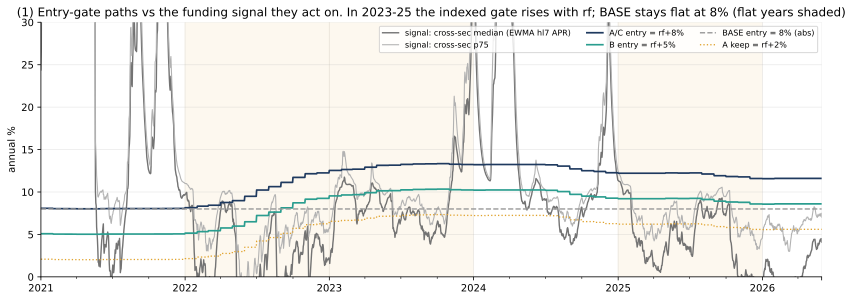

In [12]:
fig, ax = plt.subplots(figsize=(14,4.6)); shade_flat(ax)
(sig_med*100).plot(ax=ax, color='0.45', lw=1.4, label='signal: cross-sec median (EWMA hl7 APR)')
(sig_p75*100).plot(ax=ax, color='0.7', lw=1.1, label='signal: cross-sec p75')
((RF_APR+0.08)*100).plot(ax=ax, color=NAVY, lw=1.7, label='A/C entry = rf+8%')
((RF_APR+s_cost)*100).plot(ax=ax, color=TEAL, lw=1.7, ls='-', label=f'B entry = rf+{int(s_cost*100)}%')
(pd.Series(8.0,index=didx)).plot(ax=ax, color=GREY, lw=1.4, ls='--', label='BASE entry = 8% (abs)')
((RF_APR+0.02)*100).plot(ax=ax, color=AMBER, lw=1.3, ls=':', label='A keep = rf+2%')
ax.set_ylim(0,30); ax.set_ylabel('annual %'); ax.legend(ncol=3, loc='upper right', fontsize=8)
ax.set_title('(1) Entry-gate paths vs the funding signal they act on. In 2023-25 the indexed gate rises with rf; BASE stays flat at 8% (flat years shaded)')
plt.show()

C:\Users\SamuelAhou\Documents\operator\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


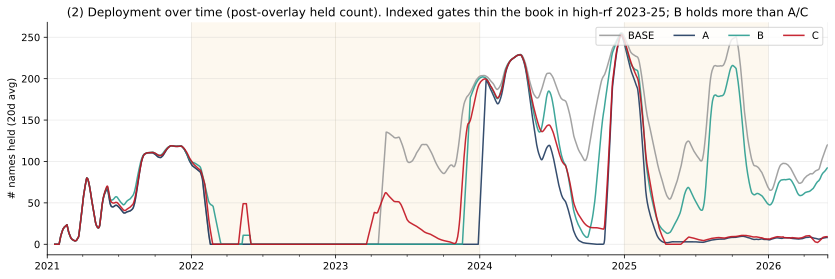

In [13]:
fig, ax = plt.subplots(figsize=(14,4.2)); shade_flat(ax)
for v in BK:
    (BK[v]['deployed'].rolling(20).mean()).plot(ax=ax, color=VCOL[v], lw=1.5, alpha=0.9, label=f'{v}')
ax.set_ylabel('# names held (20d avg)'); ax.legend(ncol=4, loc='upper right')
ax.set_title('(2) Deployment over time (post-overlay held count). Indexed gates thin the book in high-rf 2023-25; B holds more than A/C')
plt.show()

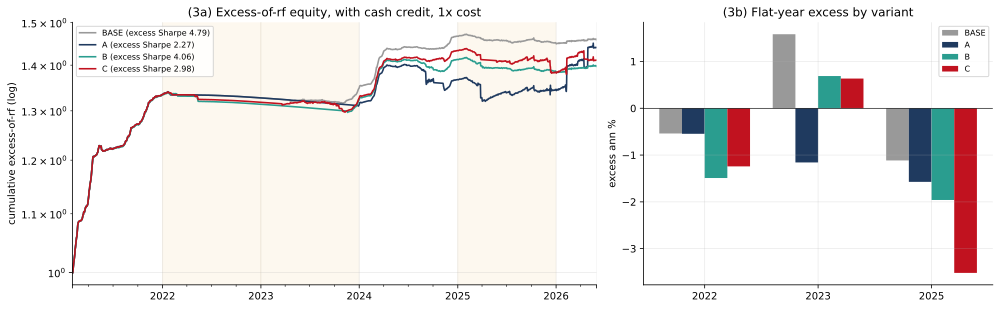

In [14]:
fig, (a1,a2) = plt.subplots(1,2,figsize=(14,4.4), gridspec_kw={'width_ratios':[1.5,1]})
for v in BK:
    _, ex, _ = series_for(BK[v], 1.0, True)
    ((1+ex).cumprod()).plot(ax=a1, color=VCOL[v], lw=1.6, label=f'{v} (excess Sharpe {ex.mean()*365/(ex.std()*np.sqrt(365)):.2f})')
shade_flat(a1); a1.set_yscale('log'); a1.set_ylabel('cumulative excess-of-rf (log)'); a1.legend(fontsize=8)
a1.set_title('(3a) Excess-of-rf equity, with cash credit, 1x cost')
# flat-year excess bars (with cash, 1x)
x = np.arange(len(FLAT)); w = 0.2
for i,v in enumerate(BK):
    a2.bar(x+(i-1.5)*w, [year_excess(BK[v],1.0,True).get(y,0) for y in FLAT], w, color=VCOL[v], label=v)
a2.axhline(0,color='k',lw=0.6); a2.set_xticks(x); a2.set_xticklabels(FLAT); a2.set_ylabel('excess ann %')
a2.legend(fontsize=8); a2.set_title('(3b) Flat-year excess by variant')
plt.tight_layout(); plt.show()

## 5. Ship-bar evaluation --- pass/fail per variant

For each indexed variant vs BASE, at **both** cost levels (headline = with cash credit, the v9-would-ship basis):
1. **flat-year improvement** --- 2023 AND 2025 excess both improve vs BASE (robustly, both costs);
2. **full-sample excess Sharpe not worse** than BASE;
3. **no material 2021/2024 damage** --- excess give-up > 1pp in either year = damage.
A variant ships only if it clears all three at both costs. A null is a fully acceptable, documented outcome.

In [15]:
def verdict(v, cash=True):
    out = {}
    for m in (1.0,2.0):
        yB, yV = year_excess(BK['BASE'],m,cash), year_excess(BK[v],m,cash)
        d23 = yV.get(2023,np.nan)-yB.get(2023,np.nan); d25 = yV.get(2025,np.nan)-yB.get(2025,np.nan)
        d21 = yV.get(2021,np.nan)-yB.get(2021,np.nan); d24 = yV.get(2024,np.nan)-yB.get(2024,np.nan)
        srB, srV = full_stats(BK['BASE'],m,cash)['excess Sharpe'], full_stats(BK[v],m,cash)['excess Sharpe']
        out[f'{int(m)}x'] = {'d2023 pp':round(d23,2),'d2025 pp':round(d25,2),'d2021 pp':round(d21,2),
                             'd2024 pp':round(d24,2),'exSR B->V':f'{srB:.2f}->{srV:.2f}',
                             'flat_up': (d23>0 and d25>0), 'SR_ok': srV>=srB-1e-9,
                             'no_dmg': (d21>-1.0 and d24>-1.0)}
    return out
for v in ('A','B','C'):
    r = verdict(v, cash=True)
    ships = all(r[m]['flat_up'] and r[m]['SR_ok'] and r[m]['no_dmg'] for m in ('1x','2x'))
    print(f'=== variant {v}  ->  {"SHIP" if ships else "NULL"} (with cash, both costs) ===')
    print(pd.DataFrame(r).T.to_string()); print()

=== variant A  ->  NULL (with cash, both costs) ===
   d2023 pp d2025 pp d2021 pp d2024 pp   exSR B->V flat_up  SR_ok no_dmg
1x    -2.74    -0.46     0.01    -4.28  4.79->2.27   False  False  False
2x    -1.42    -1.95     0.01    -7.44  3.24->1.28   False  False  False

=== variant B  ->  NULL (with cash, both costs) ===
   d2023 pp d2025 pp d2021 pp d2024 pp   exSR B->V flat_up  SR_ok no_dmg
1x    -0.89    -0.84    -0.08    -1.86  4.79->4.06   False  False  False
2x     0.33    -2.45      0.0    -3.95  3.24->2.09   False  False  False

=== variant C  ->  NULL (with cash, both costs) ===
   d2023 pp d2025 pp d2021 pp d2024 pp   exSR B->V flat_up  SR_ok no_dmg
1x    -0.95     -2.4    -0.01    -0.67  4.79->2.98   False  False   True
2x    -3.07    -3.27     0.19    -1.62  3.24->1.48   False  False  False



## Verdict --- NULL. rf-indexed gates do not improve the flat years and damage the rich years.

All three indexed variants **fail the ship bar at both cost levels** (section 5). The construction is sound
--- the gates nest the incumbent exactly at rf~0 (2021: A-BASE = +0.009pp, held-sets 100% identical) --- so
this is an *economic* failure of the mechanism, not a bug.

**The numbers (with cash credit, the v9-would-ship basis).**
- **Full-sample excess Sharpe drops** vs BASE at both costs: BASE 4.79 / 3.24 -> A 2.27 / 1.28, B 4.06 / 2.09,
  C 2.98 / 1.48. maxDD worsens too (BASE -0.88% -> A -3.1%, and -8.0% at 2x).
- **2023, the motivating year, gets WORSE, not better:** BASE +1.58% -> A -1.16%, B +0.69%, C +0.64% (1x).
  No variant beats BASE in the year the mechanism was designed for.
- **2024, the rich OOS control, is materially damaged:** BASE +8.43% -> A +4.14%, B +6.57%, C +7.76%.

**Why it backfires --- three mechanisms.**
1. **The entry premium becomes punitive vs compressed supply.** The 8% premium was calibrated to 2021's
   ~45% median funding. In the flat years supply compressed to 1.8-9.2% (2022/2023) while rf rose, so
   `rf+8%` pushes the entry gate to 10-13% --- *above the entire signal distribution* (2023 p75 = 11.3%).
   BASE's absolute 8% still sits *below* the 2023 median (9.2%) and harvests the bulk of the year's carry;
   the indexed gate forgoes it.
2. **The indexed ENTRY gate locks the book OUT in 2023** --- the opposite of the intended "drop sub-hurdle
   names." Variant A enters almost nothing (2023 deployment 0.8%, idle 99%) and sits in cash earning
   0.75x rf (a -0.25x rf drag), which is *why* its 2023 excess is negative.
3. **The raised KEEP gate evicts still-profitable names in rich years.** In 2024 (median funding 15.8%)
   A's `rf+2%` = 7.0% keep gate drops **35.4%** of BASE-held name-days (-4.28pp); those names were paying
   positive net carry. C (`rf+0%`) drops 26.6% (-0.67pp), B (`rf+1%`) 19.2% (-1.86pp). Turnover rises to
   15-16x (from 11.8x), compounding the loss.

**The owner's concern, answered.**
- **2024 keep-gate:** yes, it costs money --- the raised keep-gate is the dominant damage channel (-4.3pp for A).
- **2025 deployment:** the book does not go fully idle (2024 carryover holds days-deployed ~100% for A/B,
  84% for C), but effective breadth collapses (A 27.7 names vs BASE 144.5) and the thin residual earns
  *less* (A -1.57% vs BASE -1.12%). Low deployment here forgoes carry that *cleared* the true hurdle rather
  than avoiding sub-hurdle names.
- **2026 A = +16.8% is noise, not signal:** A is gate-locked to ~7 names (entry 11.6% vs median 0.42%); a
  7-name book's lucky run, not a repeatable edge --- its Sharpe is still crushed.

**Reconciling with the flat-years study.** flat_years A3 found 2023's attainable +3.4% was reachable by a
*smoother / broader* config (longer halflife, wider basis cap) --- a **breadth** lever, not rf-indexing. The
study named rf-indexing as the mechanism, but the test shows that lever raises the bar in lockstep with
(compressed) supply and forgoes carry instead of sharpening selection. **B (the derived rf+5%/rf+1%) is the
least-bad of the three --- closest to break-even at 2x in 2023 (+0.33pp) --- but still a net loss on Sharpe
and every other flat/rich year.**

**Recommendation: reject. No variant is productionized as v9.** The flat-year path stays governed by BASE
(v6.1) + the v4 overlay + the v8 cash credit. If the 2023 gap is pursued, the evidence points to a
signal-smoothness / breadth test, not rf-indexed gates. This is the **8th documented null** in the
funding-carry program (after Layer-G factor sizing, Layer-H shrinkage, per-asset overlays, top-K
concentration, venue-selection, daily-funding timing, vol-regime scaling).